## 01: Exploratory Data Analysis 
### 1. Data Overview

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Kaggle-e run korle ei path bodlano lagbe
DATA_PATH = "../data/titanic_data.csv"
# Kaggle: "/kaggle/input/datasets/tariqul1/titanic-data/titanic_data.csv"

#### [Load & first look]

In [2]:
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


#### [ Info, summary, duplicates]

In [6]:
df.info()
display(df.describe())
display(df.describe(exclude="number"))
print("Duplicate rows:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


Duplicate rows: 0


### 2. Missing Values

In [4]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({"missing": missing, "percent": missing_pct})
missing_df[missing_df["missing"] > 0].sort_values("percent", ascending=False)

,missing,percent
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


### [Missing values-er chart]

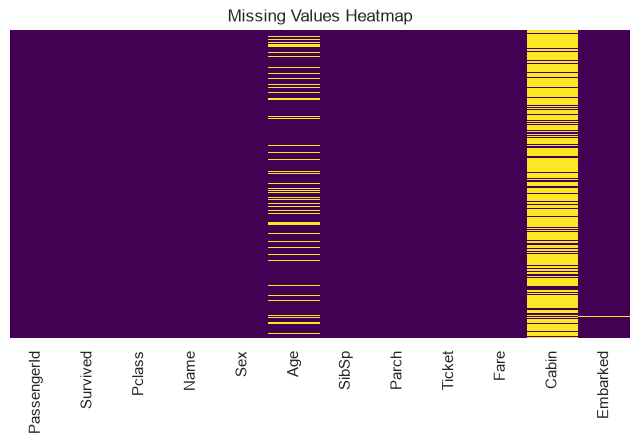

In [5]:
plt.figure(figsize=(8, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing Values Heatmap")
plt.show()

##### summary = The dataset has 891 passengers and about 38% survived. The main data quality issues are missing values: Cabin is mostly missing, Age is missing for about 20%, and Embarked for just 2 rows. Fare is highly skewed, so I will handle it during preprocessing.

## 3. Target Variable (Survived)

#### [Survived count percentage]

In [7]:
counts = df["Survived"].value_counts().sort_index()
percent = (df["Survived"].value_counts(normalize=True).sort_index() * 100).round(2)

pd.DataFrame({"count": counts, "percent": percent}).rename(
    index={0: "Did not survive", 1: "Survived"}
)

,count,percent
Survived,,
Did not survive,549,61.62
Survived,342,38.38


##### [Count plot]

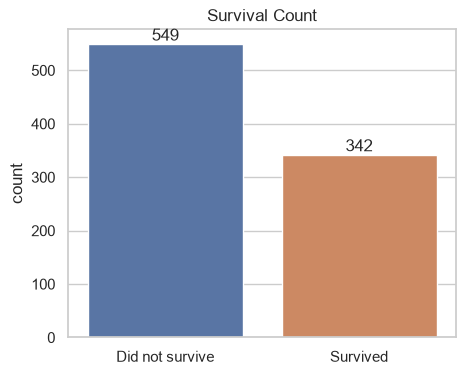

In [8]:
plt.figure(figsize=(5, 4))
ax = sns.countplot(data=df, x="Survived", hue="Survived", legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Did not survive", "Survived"])
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])
plt.title("Survival Count")
plt.xlabel("")
plt.show()

## 4. Univariate Analysis 
### 4a. Numeric Features

#### [Histograms (distribution)]

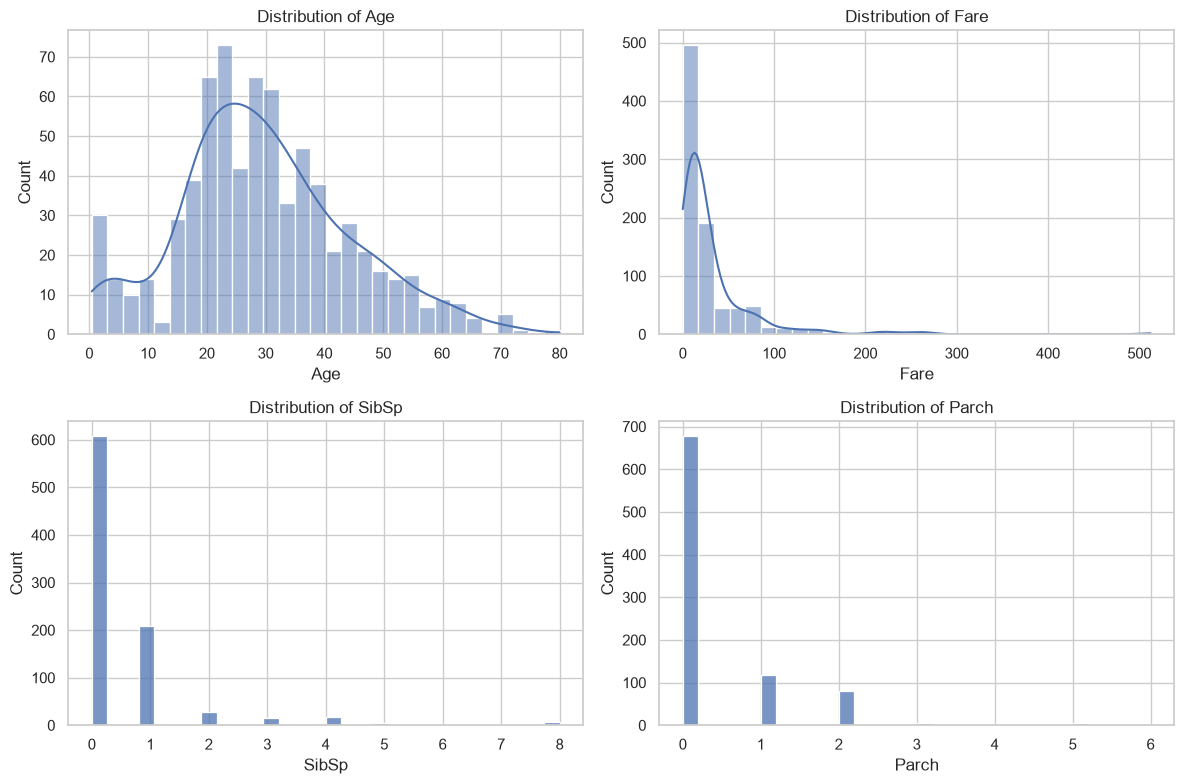

In [9]:
num_cols = ["Age", "Fare", "SibSp", "Parch"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flatten(), num_cols):
    sns.histplot(data=df, x=col, kde=(col in ["Age", "Fare"]), bins=30, ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

#### [Boxplots (outlier)]

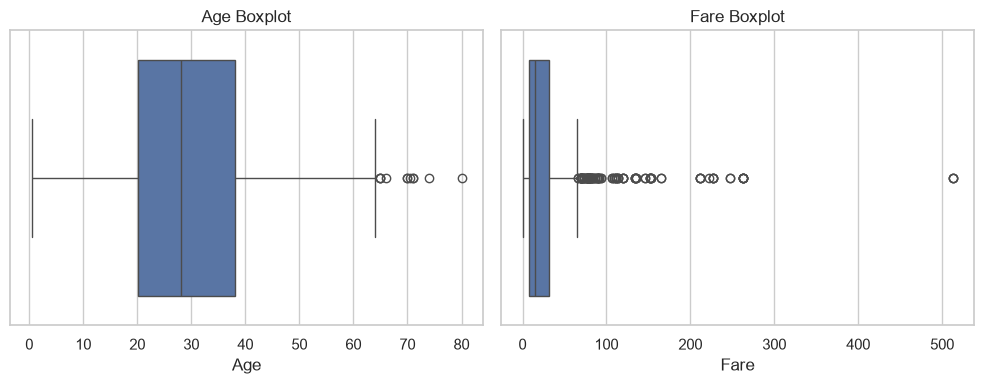

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(data=df, x="Age", ax=axes[0])
axes[0].set_title("Age Boxplot")
sns.boxplot(data=df, x="Fare", ax=axes[1])
axes[1].set_title("Fare Boxplot")
plt.tight_layout()
plt.show()

### Skewness (number diye prove)

In [11]:
df[num_cols].skew().round(2)

Age      0.39
Fare     4.79
SibSp    3.70
Parch    2.75
dtype: float64

### 4b. Categorical Features
#### [Count plots]

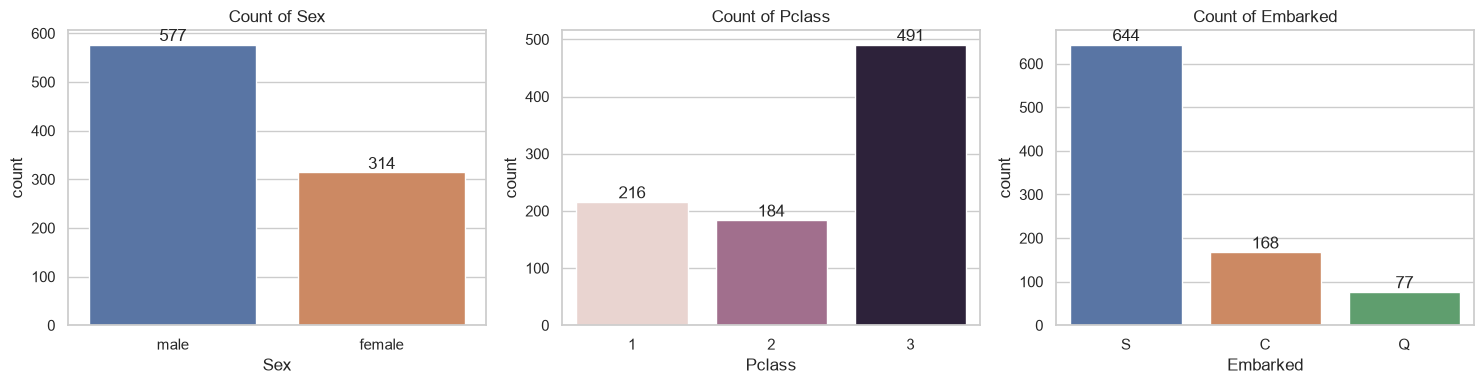

In [12]:
cat_cols = ["Sex", "Pclass", "Embarked"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, cat_cols):
    sns.countplot(data=df, x=col, hue=col, legend=False, ax=ax)
    for container in ax.containers:
        ax.bar_label(container)
    ax.set_title(f"Count of {col}")
plt.tight_layout()
plt.show()

#### summary - 549 passengers (61.6%) did not survive and 342 (38.4%) survived. The classes are moderately imbalanced, so I will check precision and recall, not only accuracy.

## 5. Bivariate Analysis (Feature vs Survived) 
### 5a. Categorical Features
##### [Survival rate table]

In [13]:
for col in ["Sex", "Pclass", "Embarked"]:
    rate = (df.groupby(col)["Survived"].mean() * 100).round(1)
    display(rate.rename(f"Survival rate % by {col}").to_frame())

,Survival rate % by Sex
Sex,
female,74.2
male,18.9


,Survival rate % by Pclass
Pclass,
1,63.0
2,47.3
3,24.2


,Survival rate % by Embarked
Embarked,
C,55.4
Q,39.0
S,33.7


##### [Bar charts]

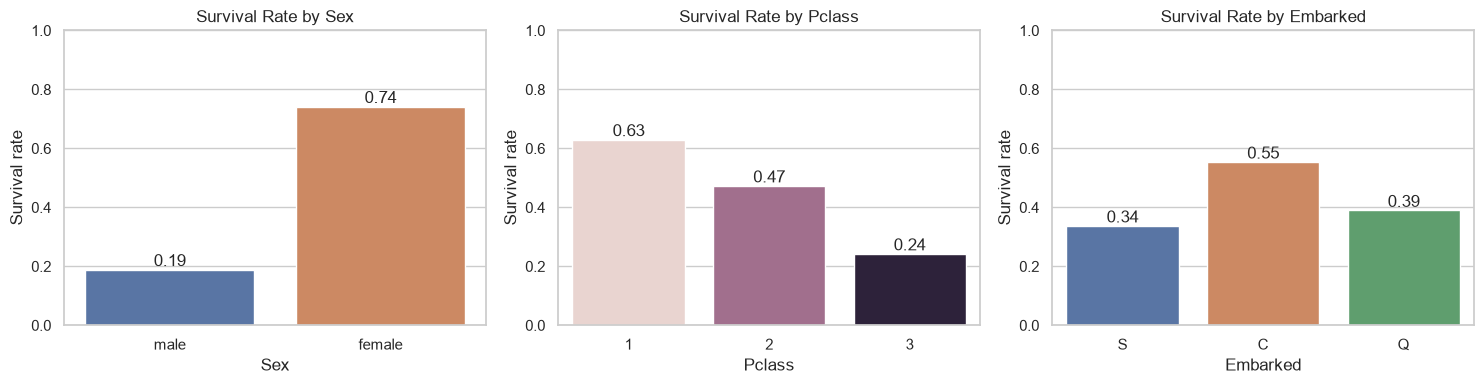

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Sex", "Pclass", "Embarked"]):
    sns.barplot(data=df, x=col, y="Survived", hue=col, legend=False,
                errorbar=None, ax=ax)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f")
    ax.set_ylim(0, 1)
    ax.set_title(f"Survival Rate by {col}")
    ax.set_ylabel("Survival rate")
plt.tight_layout()
plt.show()

### 5b. Numeric Features (Age, Fare)
##### [Age distribution, survived vs not survived]

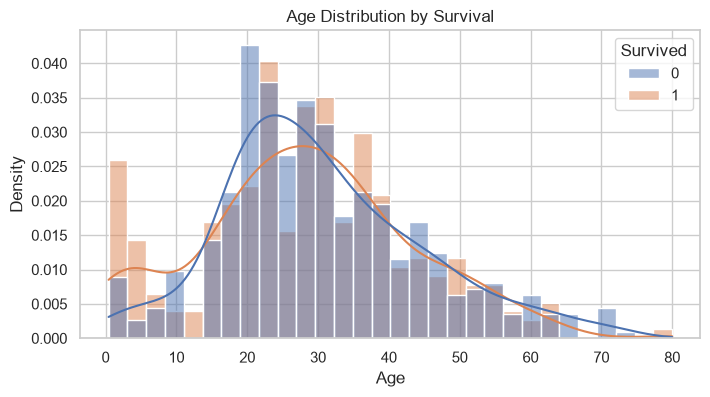

In [15]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="Age", hue="Survived", kde=True, bins=30,
             stat="density", common_norm=False)
plt.title("Age Distribution by Survival")
plt.show()

##### [Survival rate by age group]

,survival_rate_%,count
Age,,
Child (0-12),58.0,69
Teen (13-18),42.9,70
Adult (19-40),38.8,425
Middle-aged (41-60),39.1,128
Senior (61-80),22.7,22


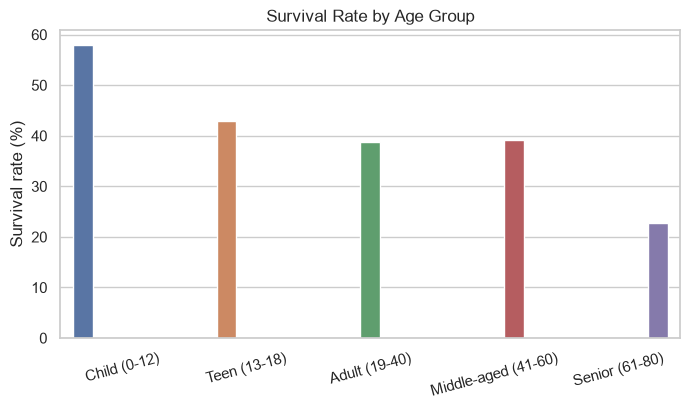

In [18]:
age_group = pd.cut(df["Age"], bins=[0, 12, 18, 40, 60, 80],
                   labels=["Child (0-12)", "Teen (13-18)", "Adult (19-40)",
                           "Middle-aged (41-60)", "Senior (61-80)"])

age_rate = df.groupby(age_group, observed=True)["Survived"].agg(["mean", "count"])
age_rate["survival_rate_%"] = (age_rate["mean"] * 100).round(1)
age_rate = age_rate[["survival_rate_%", "count"]]
display(age_rate)

plt.figure(figsize=(8, 4))
sns.barplot(x=age_rate.index, y=age_rate["survival_rate_%"],
            hue=age_rate.index, legend=False)
plt.title("Survival Rate by Age Group")
plt.ylabel("Survival rate (%)")
plt.xlabel("")
plt.xticks(rotation=15)
plt.show()

#### [Fare vs Survived]

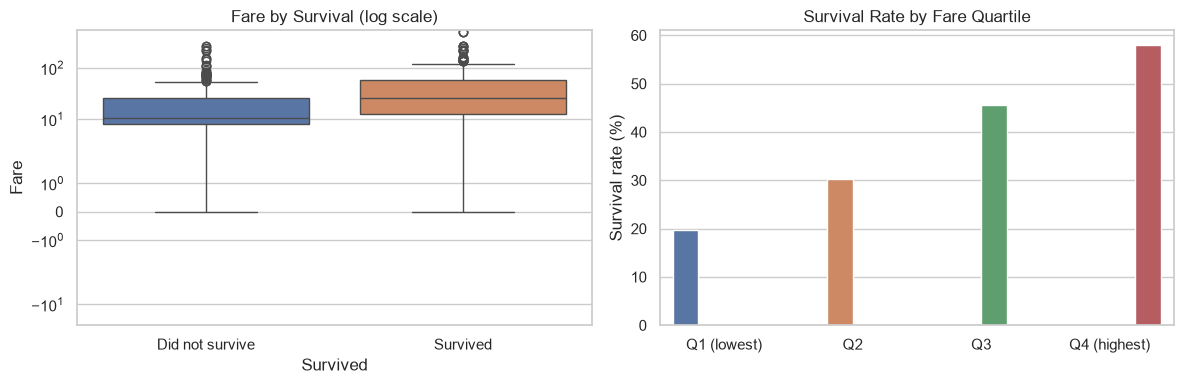

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df, x="Survived", y="Fare", hue="Survived", legend=False, ax=axes[0])
axes[0].set_yscale("symlog")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Did not survive", "Survived"])
axes[0].set_title("Fare by Survival (log scale)")

fare_bin = pd.qcut(df["Fare"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
fare_rate = df.groupby(fare_bin, observed=True)["Survived"].mean() * 100
sns.barplot(x=fare_rate.index, y=fare_rate.values, hue=fare_rate.index, legend=False, ax=axes[1])
axes[1].set_title("Survival Rate by Fare Quartile")
axes[1].set_ylabel("Survival rate (%)")
axes[1].set_xlabel("")

plt.tight_layout()
plt.show()

### 5c. Family Features
##### [SibSp, Parch ar family size]

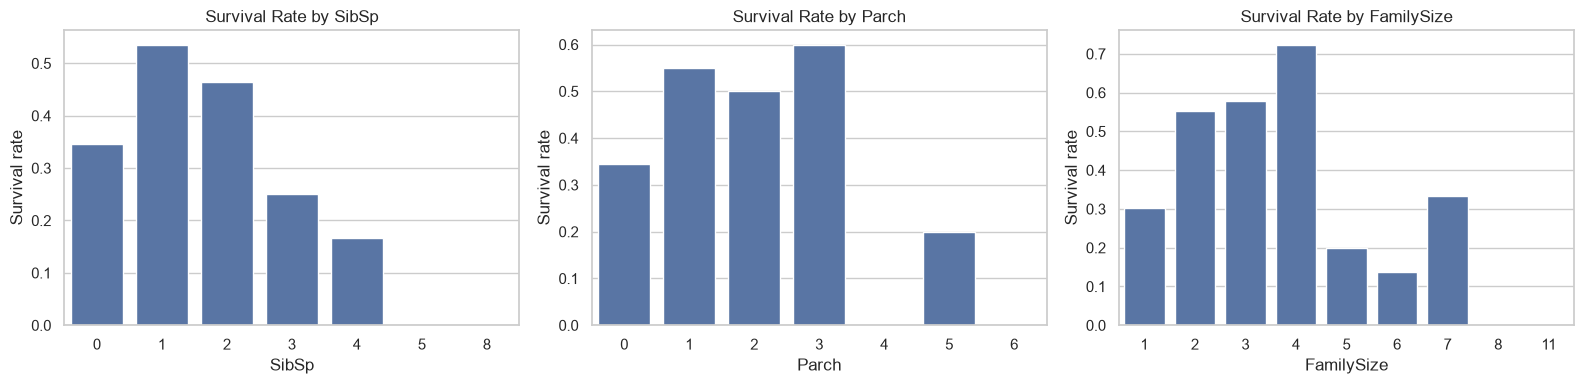

,mean,count
IsAlone,,
0,0.505650,354
1,0.303538,537


In [20]:
fam = df[["Survived", "SibSp", "Parch"]].copy()
fam["FamilySize"] = fam["SibSp"] + fam["Parch"] + 1
fam["IsAlone"] = (fam["FamilySize"] == 1).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["SibSp", "Parch", "FamilySize"]):
    sns.barplot(data=fam, x=col, y="Survived", errorbar=None, ax=ax)
    ax.set_title(f"Survival Rate by {col}")
    ax.set_ylabel("Survival rate")
plt.tight_layout()
plt.show()

display((fam.groupby("IsAlone")["Survived"].agg(["mean", "count"])))

### 5d. Is Age missing at random?
##### [Age missing-ness check]

In [21]:
age_missing = df["Age"].isnull()

print("% of Age missing, by Pclass:")
display((age_missing.groupby(df["Pclass"]).mean() * 100).round(1).to_frame("age_missing_%"))

print("% of Age missing, by Sex:")
display((age_missing.groupby(df["Sex"]).mean() * 100).round(1).to_frame("age_missing_%"))

print("Survival rate: Age missing vs present")
display((df.groupby(age_missing)["Survived"].mean() * 100).round(1)
        .rename(index={True: "Age missing", False: "Age present"}).to_frame("survival_rate_%"))

% of Age missing, by Pclass:


,age_missing_%
Pclass,
1,13.9
2,6.0
3,27.7


% of Age missing, by Sex:


,age_missing_%
Sex,
female,16.9
male,21.5


Survival rate: Age missing vs present


,survival_rate_%
Age,
Age present,40.6
Age missing,29.4


#### [summary - Gender and Pclass are the strongest factors: about 74% of women survived versus 19% of men, and 63% of 1st class versus 24% of 3rd class. Children and passengers with small families also survived more. Age is missing mostly for 3rd class passengers, so I will refine this in Section 7 using Title.]

## 6. Multivariate Analysis
### 6a. Gender and Pclass Together
##### [Gender + Pclass survival rate (pivot table)]

In [22]:
sex_class_rate = (df.pivot_table(values="Survived", index="Pclass",
                                 columns="Sex", aggfunc="mean") * 100).round(1)
sex_class_count = df.pivot_table(values="Survived", index="Pclass",
                                 columns="Sex", aggfunc="count")

print("Survival rate (%) by Pclass and Sex:")
display(sex_class_rate)
print("Number of passengers:")
display(sex_class_count)

Survival rate (%) by Pclass and Sex:


Sex,female,male
Pclass,,
1,96.8,36.9
2,92.1,15.7
3,50.0,13.5


Number of passengers:


Sex,female,male
Pclass,,
1,94,122
2,76,108
3,144,347


#### [Grouped bar chart]

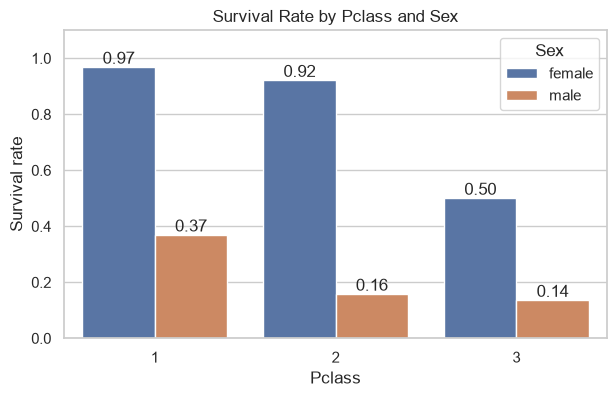

In [23]:
plt.figure(figsize=(7, 4))
ax = sns.barplot(data=df, x="Pclass", y="Survived", hue="Sex", errorbar=None)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f")
ax.set_ylim(0, 1.1)
ax.set_ylabel("Survival rate")
ax.set_title("Survival Rate by Pclass and Sex")
plt.show()

### 6b. Embarked and Pclass
##### [Kon port-e kon class-er passenger beshi]

In [24]:
embark_class_share = (pd.crosstab(df["Embarked"], df["Pclass"], normalize="index") * 100).round(1)
print("Class share (%) within each port:")
display(embark_class_share)

Class share (%) within each port:


Pclass,1,2,3
Embarked,,,
C,50.6,10.1,39.3
Q,2.6,3.9,93.5
S,19.7,25.5,54.8


#### [Class fix kore Embarked-er effect]

Survival rate (%) by Pclass and Embarked:


Embarked,C,Q,S
Pclass,,,
1,69.4,50.0,58.3
2,52.9,66.7,46.3
3,37.9,37.5,19.0


Number of passengers:


Embarked,C,Q,S
Pclass,,,
1,85,2,127
2,17,3,164
3,66,72,353


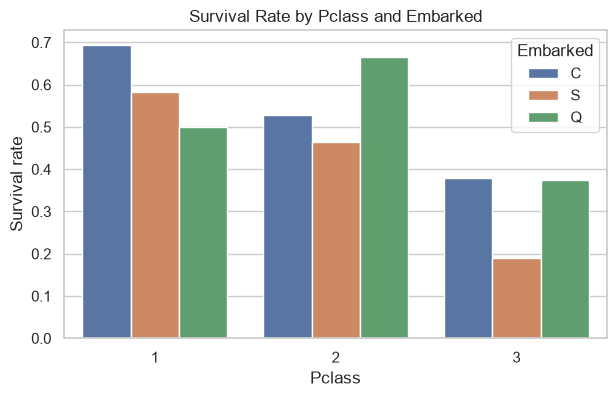

In [25]:
embark_class_rate = (df.pivot_table(values="Survived", index="Pclass",
                                    columns="Embarked", aggfunc="mean") * 100).round(1)
embark_class_count = df.pivot_table(values="Survived", index="Pclass",
                                    columns="Embarked", aggfunc="count")

print("Survival rate (%) by Pclass and Embarked:")
display(embark_class_rate)
print("Number of passengers:")
display(embark_class_count)

plt.figure(figsize=(7, 4))
sns.barplot(data=df, x="Pclass", y="Survived", hue="Embarked", errorbar=None)
plt.ylabel("Survival rate")
plt.title("Survival Rate by Pclass and Embarked")
plt.show()

### 6c. Age and Fare vs Pclass
#### Age er Fare, Pclass onujayi

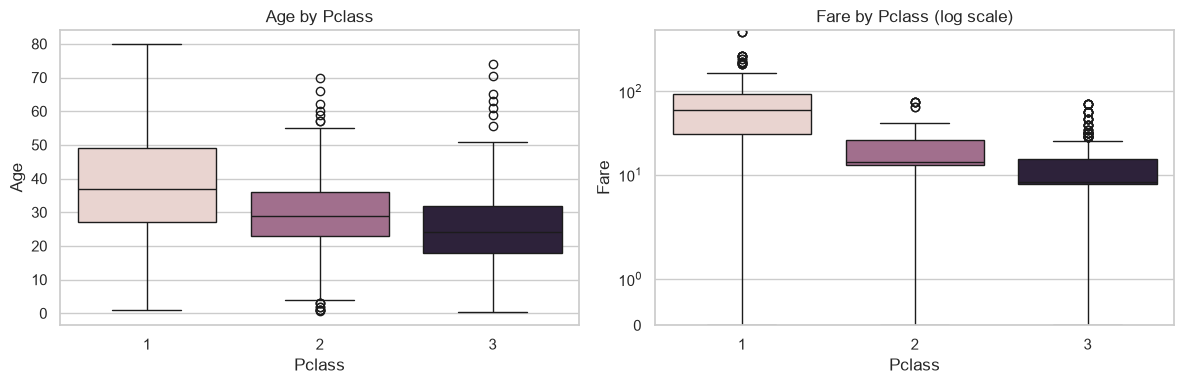

Median Age by Pclass and Sex:


Pclass  Sex   
1       female    35.0
        male      40.0
2       female    28.0
        male      30.0
3       female    21.5
        male      25.0
Name: Age, dtype: float64

Median Fare by Pclass:


Pclass
1    60.29
2    14.25
3     8.05
Name: Fare, dtype: float64

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="Pclass", y="Age", hue="Pclass", legend=False, ax=axes[0])
axes[0].set_title("Age by Pclass")
sns.boxplot(data=df, x="Pclass", y="Fare", hue="Pclass", legend=False, ax=axes[1])
axes[1].set_yscale("symlog")
axes[1].set_ylim(bottom=0)
axes[1].set_title("Fare by Pclass (log scale)")
plt.tight_layout()
plt.show()

print("Median Age by Pclass and Sex:")
display(df.groupby(["Pclass", "Sex"])["Age"].median())
print("Median Fare by Pclass:")
display(df.groupby("Pclass")["Fare"].median().round(2))

### 6d. Correlation Heatmap
#### Correlation heatmap

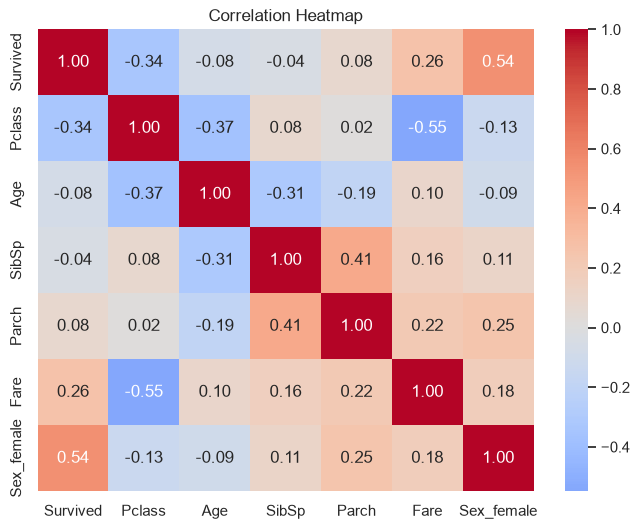

In [27]:
corr_df = df[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]].copy()
corr_df["Sex_female"] = (df["Sex"] == "female").astype(int)

plt.figure(figsize=(8, 6))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

##### summary - Sex and Pclass together matter most. Women in 1st and 2nd class survived more than 90% of the time, but 3rd-class women only 50%, and men survived much less in every class. Embarked looked important at first, but a big part of it is just class mix. Age and family size have weak linear correlation, but the charts show non-linear patterns, so I will engineer features from them.

## 7. Feature Ideas for Preprocessing
### 7a. Title from Name
##### [Title ber kora]

In [28]:
feat = df.copy()

feat["Title"] = feat["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
print(feat["Title"].value_counts())

Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64


##### [Title gulo group kora er survival rate]

In [29]:
title_map = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"}
feat["Title"] = feat["Title"].replace(title_map)

common = ["Mr", "Mrs", "Miss", "Master"]
feat["Title"] = feat["Title"].where(feat["Title"].isin(common), "Rare")

title_stats = feat.groupby("Title")["Survived"].agg(["mean", "count"])
title_stats["survival_rate_%"] = (title_stats["mean"] * 100).round(1)
display(title_stats[["survival_rate_%", "count"]].sort_values("survival_rate_%", ascending=False))

print("Median Age by Title:")
display(feat.groupby("Title")["Age"].median())

,survival_rate_%,count
Title,,
Mrs,79.4,126
Miss,70.3,185
Master,57.5,40
Rare,34.8,23
Mr,15.7,517


Median Age by Title:


Title
Master     3.5
Miss      21.0
Mr        30.0
Mrs       35.0
Rare      48.5
Name: Age, dtype: float64

### 7b. Cabin Flag
##### [has_cabin check]

In [30]:
feat["has_cabin"] = feat["Cabin"].notnull().astype(int)

display((feat.groupby("has_cabin")["Survived"].agg(["mean", "count"])))
display((pd.crosstab(feat["has_cabin"], feat["Pclass"], normalize="columns") * 100).round(1))

,mean,count
has_cabin,,
0,0.299854,687
1,0.666667,204


Pclass,1,2,3
has_cabin,,,
0,18.5,91.3,97.6
1,81.5,8.7,2.4


### 7c. Family Features
###### [FamilySize, IsAlone, FamilyGroup]

In [31]:
feat["FamilySize"] = feat["SibSp"] + feat["Parch"] + 1
feat["IsAlone"] = (feat["FamilySize"] == 1).astype(int)
feat["FamilyGroup"] = pd.cut(feat["FamilySize"], bins=[0, 1, 4, 11],
                             labels=["Alone", "Small (2-4)", "Large (5+)"])

fam_stats = feat.groupby("FamilyGroup", observed=True)["Survived"].agg(["mean", "count"])
fam_stats["survival_rate_%"] = (fam_stats["mean"] * 100).round(1)
display(fam_stats[["survival_rate_%", "count"]])

,survival_rate_%,count
FamilyGroup,,
Alone,30.4,537
Small (2-4),57.9,292
Large (5+),16.1,62


### 7d. Fare Transform
##### [log1p transform]

Skewness before: 4.79
Skewness after log1p: 0.39


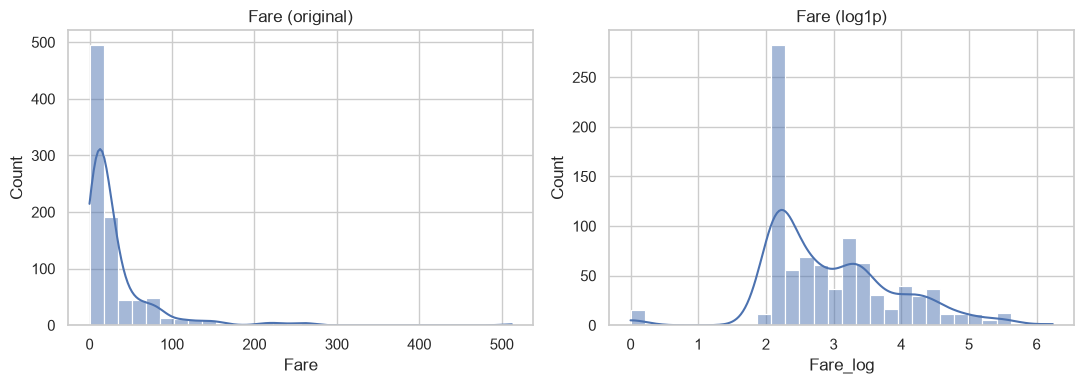

In [32]:
feat["Fare_log"] = np.log1p(feat["Fare"])

print("Skewness before:", round(feat["Fare"].skew(), 2))
print("Skewness after log1p:", round(feat["Fare_log"].skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(feat["Fare"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Fare (original)")
sns.histplot(feat["Fare_log"], bins=30, kde=True, ax=axes[1])
axes[1].set_title("Fare (log1p)")
plt.tight_layout()
plt.show()

### 7e. Preprocessing Plan

| Column | Action | Reason |
|---|---|---|
| PassengerId | Drop | Just an ID, no information |
| Ticket | Drop | 681 unique values, no clear pattern |
| Name | Drop after extracting `Title` | Unique for each passenger |
| Cabin | Drop after creating `has_cabin` | 77.1% missing |
| Age | Fill with median by `Title` | Title captures both age group and sex |
| Embarked | Fill 2 missing values with mode (S) | Only 0.22% missing |
| Fare | Create `Fare_log` with log1p | Skewness 4.79 reduced to 0.39 |
| Sex, Embarked, Title | Encode to numbers (one-hot) | Models need numeric input |
| SibSp, Parch | Replace with `FamilySize` (and `FamilyGroup` / `IsAlone`) | Correlated (0.41), and family size shows the non-linear pattern |

**Planned feature set:** `Pclass`, `Sex`, `Age`, `Title`, `FamilySize` (or `FamilyGroup`), `IsAlone`, `Fare_log`, `Embarked`, `has_cabin`.

**Data leakage rule:** First split into train and test sets, then calculate the medians and modes (for `Age` and `Embarked`) from the training set only, and apply them to both sets.

## EDA Summary
- About 38.4% of passengers survived, so the classes are moderately imbalanced.
- `Sex` and `Pclass` are the strongest factors, and they work together (for example, 96.8% survival for 1st-class women vs 13.5% for 3rd-class men).
- Children and small families survived more, so `Age` and family size have non-linear effects.
- `Age` has 19.87% missing values, mostly in 3rd class. `Cabin` is 77.1% missing.
- `Title` is a strong new feature because it combines sex and age information.

#### summary - I extracted the title from the name, because it combines sex and age: Mr survived only 15.7%, Mrs 79.4%, and young boys, called Master, 57.5%. I also created family features, because small families of 2 to 4 did best. Fare was highly skewed, so I applied a log transform. I will fill missing Age by the median of each title, and I will calculate all fill values from the training set only to avoid data leakage.